# Iris Flower Classification
**Oasis Infobyte SIP — Data Science Task 1** · Steven Manuel Rios

Goal: predict the species (Setosa, Versicolor, Virginica) from sepal/petal measurements.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

## 1. Load data
The dataset ships with scikit-learn (`load_iris`) — no download needed.

In [2]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2. EDA — shape, dtypes, nulls, descriptive statistics

In [3]:
print("Shape:", df.shape)
print(df.dtypes)
print("\nNull values per column:\n", df.isnull().sum())
df.describe()

Shape: (150, 6)
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species                  str
dtype: object

Null values per column:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [4]:
df["species"].value_counts()  # perfectly balanced: 50 per class

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## 3. Visualisations

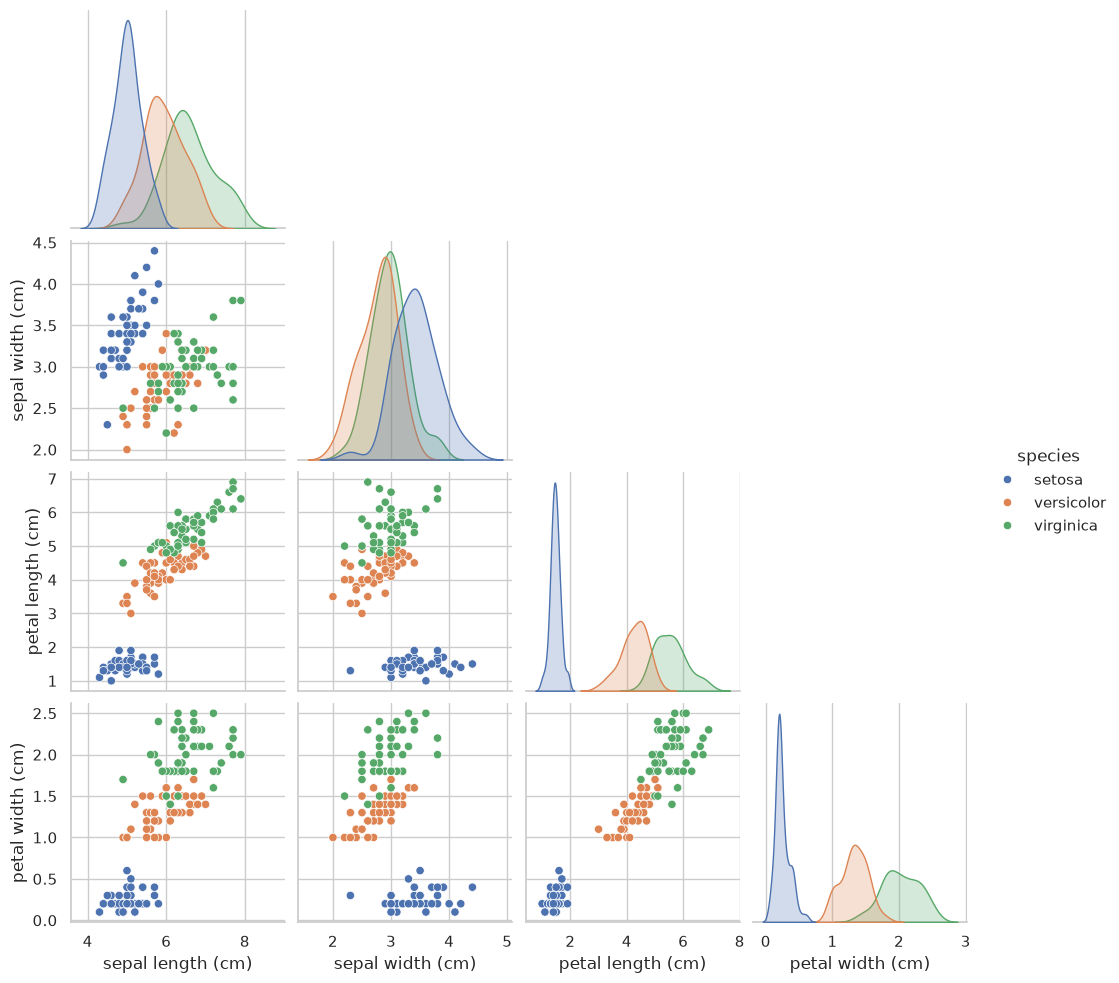

In [5]:
sns.pairplot(df.drop(columns="target"), hue="species", corner=True)
plt.savefig("screenshots/pairplot.png", dpi=100); plt.show()

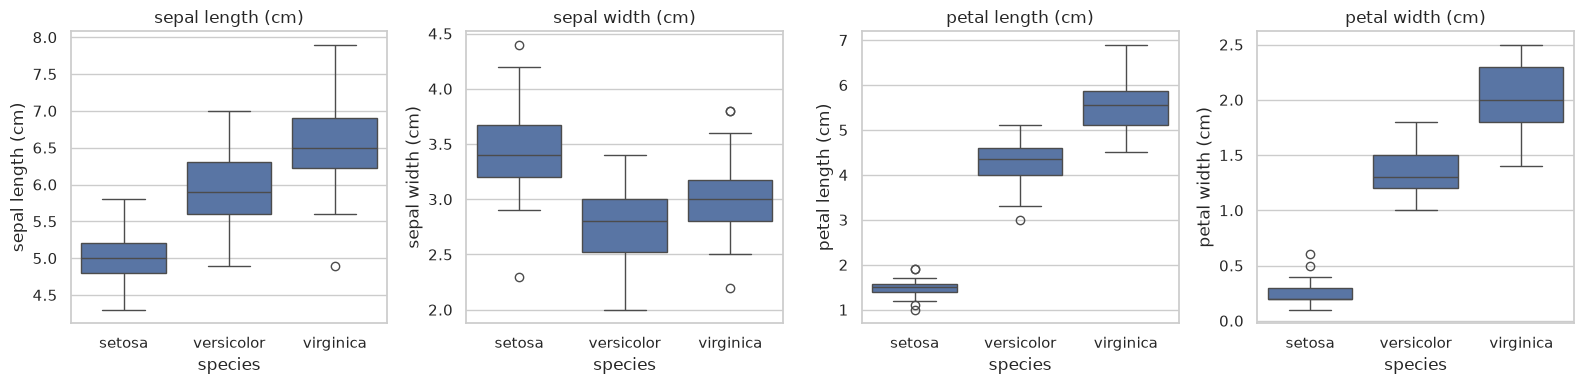

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, iris.feature_names):
    sns.boxplot(data=df, x="species", y=col, ax=ax)
    ax.set_title(col)
save("boxplots")

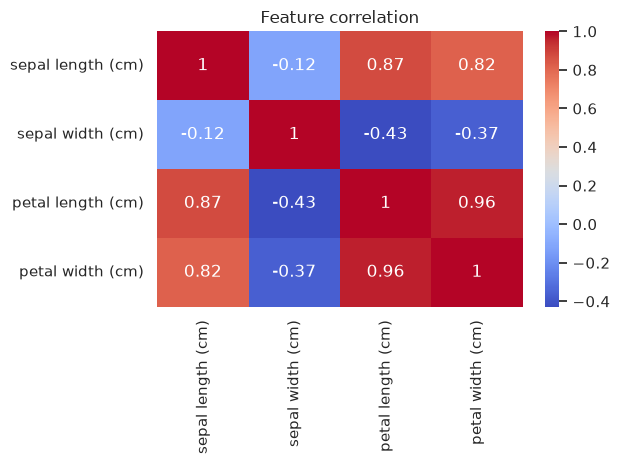

In [7]:
sns.heatmap(df[iris.feature_names].corr(), annot=True, cmap="coolwarm"); plt.title("Feature correlation"); save("correlation")

## 4. Feature selection discussion
The pairplot and box plots show **petal length** and **petal width** separate the species almost perfectly: Setosa has no overlap at all, and Versicolor/Virginica overlap only slightly. Sepal width is the weakest feature, since all three species overlap heavily. Petal length and width are also strongly correlated (r ≈ 0.96), so they carry very similar information. Tree-based feature importance (below) confirms this.

## 5. Train/test split (80/20, stratified)

In [8]:
from sklearn.model_selection import train_test_split
X, y = df[iris.feature_names], df["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train.shape, X_test.shape

((120, 4), (30, 4))

## 6. Train and evaluate four classifiers

===== Logistic Regression =====
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

===== KNN (k=5) =====
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

===== Decision Tree =====
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90   

===== Random Forest =====
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



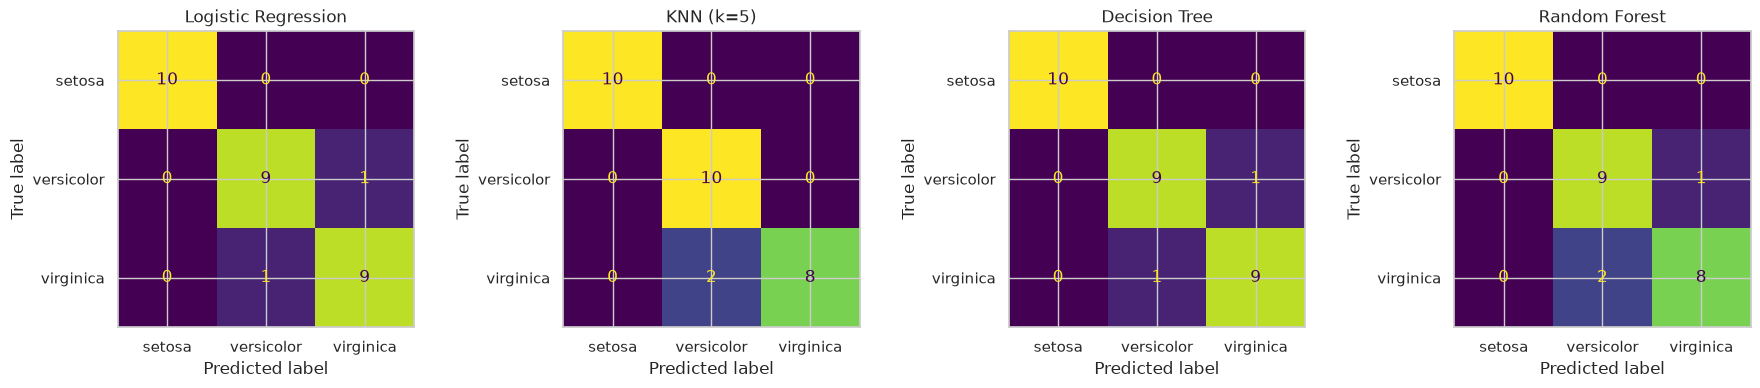

,test_accuracy,cv5_accuracy
Random Forest,0.900000,0.966667
Logistic Regression,0.933333,0.960000
KNN (k=5),0.933333,0.960000
Decision Tree,0.933333,0.953333


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
results = {}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, m) in zip(axes, models.items()):
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    cv = cross_val_score(m, X, y, cv=5).mean()
    results[name] = {"test_accuracy": accuracy_score(y_test, pred), "cv5_accuracy": cv}
    print(f"===== {name} =====\n", classification_report(y_test, pred))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False); ax.set_title(name)
save("confusion_matrices")
pd.DataFrame(results).T.sort_values("cv5_accuracy", ascending=False)

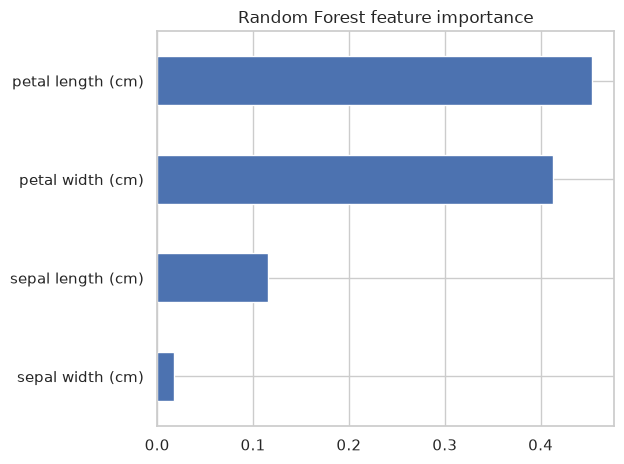

In [10]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=iris.feature_names).sort_values()
imp.plot.barh(title="Random Forest feature importance"); save("feature_importance")

## 7. Best model
The test set has only 30 samples, so one misclassification moves accuracy by 3.3 points. I therefore rank by **5-fold cross-validated accuracy**. **Random Forest** scores highest (≈96.7% CV accuracy). It handles the slight Versicolor/Virginica overlap well and needs no feature scaling. Logistic Regression and KNN are close behind (96.0% CV) and score slightly higher on this particular test split (93.3% vs 90.0%), so either is a reasonable simpler alternative. **Best model: Random Forest**, because its cross-validated performance is the most stable.